In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SingleAgent import *

## Theoretical Qlearning values

In [24]:
delta_value = 0.99
epsilon_value = 0.1
P, R, T, S = 0.2, 0.8, 1, 0

The Payoff Matrix:

| **Player A / Player B** | **Cooperate (C)** | **Defect (D)** |
|-------------------------|-------------------|----------------|
| **Cooperate (C)**       | R = 0.8           | S = 0          |
| **Defect (D)**          | T = 1.0           | P = 0.2        |

## Single Run

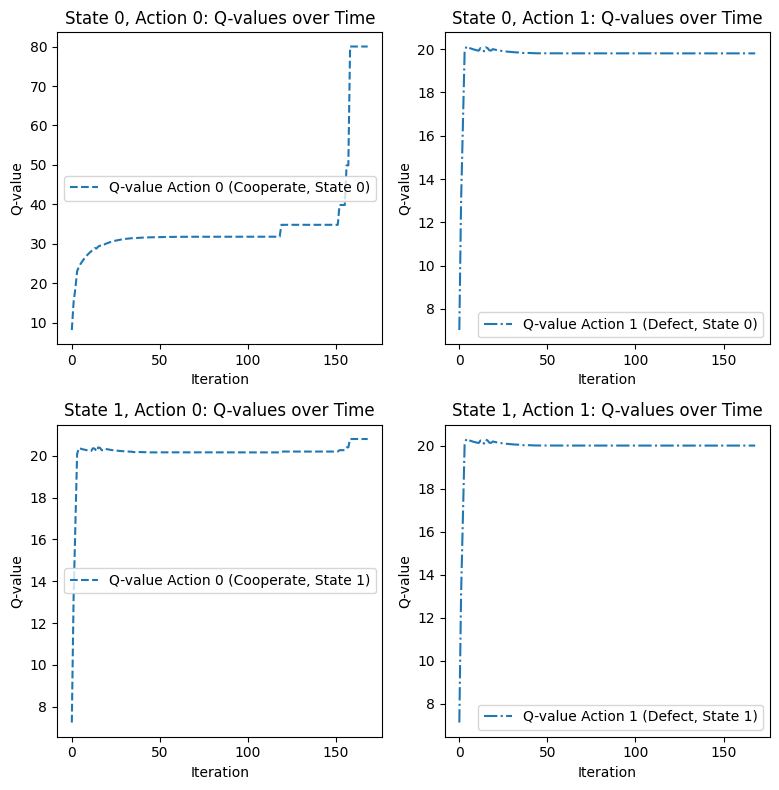

Cooperations: 171, Defections: 583


In [25]:
# Initialize the solver with GrimTrigger_QValues
strategy = GrimTrigger_QValues()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=epsilon_value,
    lambda_val=0.1,
    alpha=0.1,
    delta=delta_value,
    K=500,
    M=5,
    e_decay=0.85,
    random_uniform=True,
    verbose=False
)

# Run the solver
cooperations, defections, q1_history, mean_q_values, grim_trigger_count_dict, initial_q_value = solver.run()
# Check results
print(f"Cooperations: {cooperations}, Defections: {defections}")


### Calculate Theoretical Q-Values

In [36]:
def calculate_q_values(epsilon, delta, P, R, T, S):
    """
    Calculate the Q-values for the reduced system based on the Grim Trigger strategy.
    
    Parameters:
        epsilon (float): The noise parameter (probability of random defection/cooperation).
        delta (float): The discount factor (future rewards weight).
        P (float): The payoff for both players defecting (Punishment).
        R (float): The payoff for both players cooperating (Reward).
        T (float): The payoff for defecting when the opponent cooperates (Temptation).
        S (float): The payoff for cooperating when the opponent defects (Sucker's payoff).
    
    Returns:
        tuple: (Q00, Q01, Q10, Q11)
    """
    
    # Calculate Q11 first, as it is required for other values
    Q11 = ((1 - epsilon / 2) * P + (epsilon / 2) * T) / (1 - delta)
    
    # Calculate Q00 based on Q11
    numerator_Q00 = (1 - epsilon / 2) * R + (epsilon / 2) * S + (epsilon / 2) * delta * Q11
    denominator_Q00 = 1 - (1 - epsilon / 2) * delta
    Q00 = numerator_Q00 / denominator_Q00
    
    # Calculate Q01 based on Q11
    Q01 = (1 - epsilon / 2) * T + (epsilon / 2) * P + delta * Q11
    
    # Calculate Q10 based on Q00 and Q11
    numerator_Q10 = (1 - epsilon / 2) * S + (epsilon / 2) * R + (epsilon / 2) * delta * Q00
    denominator_Q10 = 1 - (1 - epsilon / 2) * delta
    Q10 = numerator_Q10 / denominator_Q10
    
    return Q00, Q01, Q10, Q11

P = 0.2        # Punishment payoff
R = 0.8        # Reward payoff
T = 1.0        # Temptation payoff
S = 0.0        # Sucker's payoff

Q00, Q01, Q10, Q11 = calculate_q_values(epsilon_value, delta_value, P, R, T, S)

print(f"Q00 = {Q00:.4f}, Q01 = {Q01:.4f}, Q10 = {Q10:.4f}, Q11 = {Q11:.4f}")


Q00 = 32.7395, Q01 = 24.7200, Q10 = 27.9093, Q11 = 24.0000


### Value Iteration Check

In [27]:
qval_inner_value_iteration = solver.check_value_iteration()

In [28]:
dfs = convert_dict_to_mean_df(qval_inner_value_iteration, mean=False)

In [29]:
mean_rows = []
max_length = max(len(df) for df in dfs)
for i in range(max_length):
    row_means = []

    for df in dfs:
        if i < len(df):  # If the row exists in this DataFrame
            row_means.append(df.iloc[i][['Q1', 'Q2', 'Q3', 'Q4']].values)
        else:  # If the row does not exist, append NaNs
            row_means.append([np.nan, np.nan, np.nan, np.nan])

    # Compute the mean for each column (Q1, Q2, Q3, Q4) across all DataFrames
    mean_row = np.nanmean(row_means, axis=0)  # np.nanmean ignores NaN values

    mean_rows.append(mean_row)

# Convert the list of row-wise means into a DataFrame
mean_df = pd.DataFrame(mean_rows, columns=['Q1', 'Q2', 'Q3', 'Q4'])

In [30]:
def create_line(value, length=10):
    """
    Create a line of repeated values.

    Parameters:
        value (float): The value to repeat.
        length (int): The number of times to repeat the value.

    Returns:
        list: A list containing the repeated values.
    """
    return [value for _ in range(length)]

In [31]:
initial_q_value

[array([[0.06760108, 0.57223132],
        [0.44632484, 0.19475091]]),
 array([[0.89058297, 0.36431446],
        [0.83680278, 0.22090379]]),
 array([[0.42952479, 0.52004497],
        [0.90215326, 0.33241425]]),
 array([[0.47100525, 0.36836935],
        [0.93783262, 0.81430146]]),
 array([[0.34845601, 0.49297245],
        [0.20692113, 0.95185387]])]

starting Q1 for the sampling number 0 is 0.4299415016310396
starting Q1 for the sampling number 1 is 0.13134182247076348
starting Q1 for the sampling number 2 is 1.2027038029382666
starting Q1 for the sampling number 3 is 0.7231755058019925
starting Q1 for the sampling number 4 is 1.7117904111060733
starting Q2 for the sampling number 0 is 0.4299415016310396
starting Q2 for the sampling number 1 is 1.7339391049479727
starting Q2 for the sampling number 2 is 1.2027038029382666
starting Q2 for the sampling number 3 is 1.2891484828562823
starting Q2 for the sampling number 4 is 0.42161106375210466
starting Q3 for the sampling number 0 is 0.6299415016310397
starting Q3 for the sampling number 1 is 0.3313418224707635
starting Q3 for the sampling number 2 is 1.9389097294580744
starting Q3 for the sampling number 3 is 0.9231755058019926
starting Q3 for the sampling number 4 is 1.4216110637521047
starting Q4 for the sampling number 0 is 0.6299415016310397
starting Q4 for the sampling number 1 

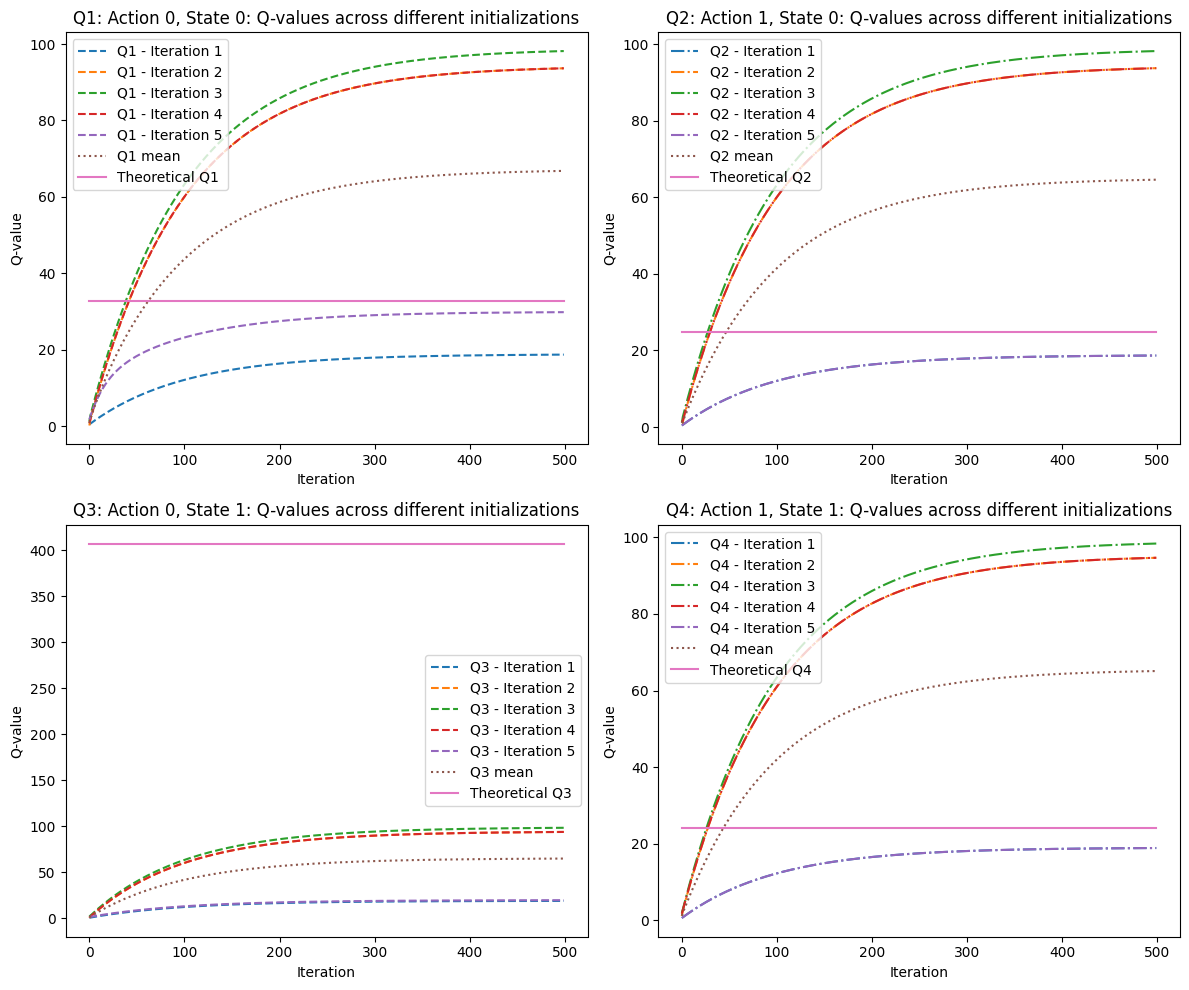

In [32]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
# Plot all Q1 values from all DataFrames in a single subplot
for i in range(len(dfs)):
    print(f"starting Q1 for the sampling number {i} is {dfs[i]['Q1'][0]}")
    axs[0, 0].plot(dfs[i]['Q1'], linestyle='--', label=f"Q1 - Iteration {i+1}")
axs[0, 0].plot(mean_df['Q1'], linestyle=':', label=f"Q1 mean")
axs[0, 0].plot(create_line(Q00, len(mean_df)), linestyle='solid', label=f"Theoretical Q1")


axs[0, 0].set_title("Q1: Action 0, State 0: Q-values across different initializations")
axs[0, 0].set_xlabel("Iteration")
axs[0, 0].set_ylabel("Q-value")
axs[0, 0].legend()

# Plot all Q2 values from all DataFrames in a single subplot
for i in range(len(dfs)):
    print(f"starting Q2 for the sampling number {i} is {dfs[i]['Q2'][0]}")

    axs[0, 1].plot(dfs[i]['Q2'], linestyle='-.', label=f"Q2 - Iteration {i+1}")
axs[0, 1].plot(mean_df['Q2'], linestyle=':', label=f"Q2 mean")
axs[0, 1].plot(create_line(Q01, len(mean_df)), linestyle='solid', label=f"Theoretical Q2")


axs[0, 1].set_title("Q2: Action 1, State 0: Q-values across different initializations")
axs[0, 1].set_xlabel("Iteration")
axs[0, 1].set_ylabel("Q-value")
axs[0, 1].legend()

# Plot all Q3 values from all DataFrames in a single subplot
for i in range(len(dfs)):
    print(f"starting Q3 for the sampling number {i} is {dfs[i]['Q3'][0]}")
    axs[1, 0].plot(dfs[i]['Q3'], linestyle='--', label=f"Q3 - Iteration {i+1}")
axs[1, 0].plot(mean_df['Q3'], linestyle=':', label=f"Q3 mean")
axs[1, 0].plot(create_line(Q10, len(mean_df)), linestyle='solid', label=f"Theoretical Q3")


axs[1, 0].set_title("Q3: Action 0, State 1: Q-values across different initializations")
axs[1, 0].set_xlabel("Iteration")
axs[1, 0].set_ylabel("Q-value")
axs[1, 0].legend()

# Plot all Q4 values from all DataFrames in a single subplot
for i in range(len(dfs)):
    print(f"starting Q4 for the sampling number {i} is {dfs[i]['Q4'][0]}")
    axs[1, 1].plot(dfs[i]['Q4'], linestyle='-.', label=f"Q4 - Iteration {i+1}")
axs[1, 1].plot(mean_df['Q4'], linestyle=':', label=f"Q4 mean")
axs[1, 1].plot(create_line(Q11, len(mean_df)), linestyle='solid', label=f"Theoretical Q4")


axs[1, 1].set_title("Q4: Action 1, State 1: Q-values across different initializations")
axs[1, 1].set_xlabel("Iteration")
axs[1, 1].set_ylabel("Q-value")
axs[1, 1].legend()


for i in range(len(dfs)):
    if dfs[i]['Q1'][0] > dfs[i]['Q2'][0]:
        print(f'Starting Condition for sampling n° {i} is cooperating in State 0')

    elif dfs[i]['Q1'][0] < dfs[i]['Q2'][0]:
        print(f'Starting Condition for sampling n° {i} is defecting in State 0')
    
    elif dfs[i]['Q1'][0] == dfs[i]['Q2'][0]:
        print(f'Starting Condition for sampling n° {i} is exactly the same value for Q00 and Q01 in State 0')
    else:
        raise KeyError
    
    if dfs[i]['Q3'][0] > dfs[i]['Q4'][0]:
        print(f'Starting Condition for sampling n° {i} is cooperating in State 1')

    elif dfs[i]['Q3'][0] < dfs[i]['Q4'][0]:
        print(f'Starting Condition for sampling n° {i} is defecting in State 1')
    elif dfs[i]['Q3'][0] == dfs[i]['Q4'][0]:
        print(f'Starting Condition for sampling n° {i} is exactly the same value for Q10 and Q11 in State 1')

    else:
        raise KeyError
    


# Adjust the layout to avoid overlapping
plt.tight_layout()

# Show the plot for all Q-values combined
plt.show()

In [20]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

## Multiple Random Seed

In [ ]:
seeds = random.sample(range(1, 10000), 10)

all_cooperations = []
all_defections = []

for seed in seeds:
    random.seed(seed)
    strategy = GrimTrigger_QValues()  # Or use TitForTat()
    solver = PrisonersDilemmaSolver(strategy, e_initial=epsilon_value, 
                                    lambda_val=0.1, 
                                    alpha=0.05, 
                                    delta=0.9, 
                                    K=100, 
                                    M=10, 
                                    e_decay=0.95, 
                                    verbose=False, plotting = False)
    
    cooperations, defections, q = solver.run()
    all_cooperations.append(cooperations)
    all_defections.append(defections)

all_cooperations = np.array(all_cooperations)
all_defections = np.array(all_defections)

mean_cooperations = np.mean(all_cooperations)
mean_defections = np.mean(all_defections)

print(f"Mean cooperations: {mean_cooperations}")
print(f"Mean defections: {mean_defections}")


NameError: name 'random' is not defined

## Critical Value of delta

In [ ]:
## Should this be changed, putting how many times it learns to play gt instead or number of cooperations?
break

In [ ]:
def analyze_critical_delta(strategy, e_initial, lambda_val, alpha, delta_range, K, M, e_decay, random_uniform=True):
    """
    Analyzes the critical value of delta for which the agent begins cooperating against the Grim Trigger strategy.
    
    Parameters:
        strategy: The opponent strategy (e.g., GrimTrigger).
        e_initial: Initial exploration rate for Q-learning.
        lambda_val: Eligibility decay parameter.
        alpha: Learning rate for Q-learning.
        delta_range: Tuple specifying the range of delta (min, max, step).
        K: Number of iterations per episode.
        M: Number of episodes to train.
        e_decay: Decay rate for exploration rate.
        random_uniform: Whether to initialize Q-values randomly.
    
    Returns:
        A plot of cooperation ratio vs. delta.
    """
    deltas = np.arange(delta_range[0], delta_range[1], delta_range[2])
    cooperation_ratios = []

    for delta in deltas:
        print(f"Running for delta = {delta:.2f}...")  # Verbose output to track progress
        # Initialize the solver for the given delta
        solver = PrisonersDilemmaSolver(
            strategy=strategy,
            e_initial=e_initial,
            lambda_val=lambda_val,
            alpha=alpha,
            delta=delta,
            K=K,
            M=M,
            e_decay=e_decay,
            random_uniform=random_uniform,
            verbose=False,
            plotting=False  # Suppress plotting for individual runs
        )
        # Run the solver and collect results
        cooperations, defections, _, _, = solver.run()

        # Calculate cooperation ratio
        total_actions = cooperations + defections
        cooperation_ratio = cooperations / total_actions if total_actions > 0 else 0
        cooperation_ratios.append(cooperation_ratio)

    # Plot the cooperation ratio as a function of delta
    plt.figure(figsize=(10, 6))
    plt.plot(deltas, cooperation_ratios, marker='o', linestyle='-', label="Cooperation Ratio")
    plt.axhline(y=0.5, color='r', linestyle='--', label="50% Cooperation Threshold")
    plt.xlabel("Delta (Discount Factor)")
    plt.ylabel("Cooperation Ratio")
    plt.title("Cooperation Ratio vs. Delta in Prisoner's Dilemma")
    plt.legend()
    plt.grid()
    plt.show()

    # Return raw data for further analysis if needed
    return deltas, cooperation_ratios


Running for delta = 0.50...
Running for delta = 0.55...
Running for delta = 0.60...
Running for delta = 0.65...
Running for delta = 0.70...
Running for delta = 0.75...
Running for delta = 0.80...
Running for delta = 0.85...
Running for delta = 0.90...


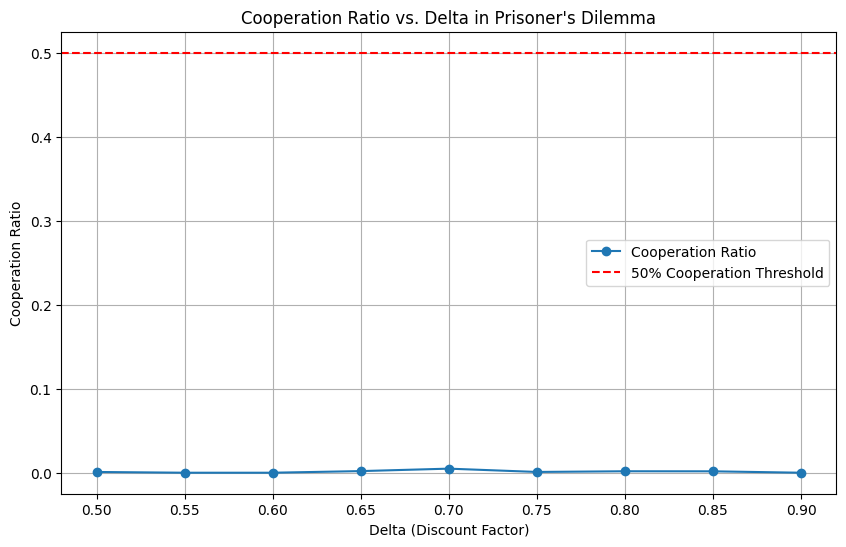

In [ ]:
# Define parameters for the experiment
strategy = GrimTrigger_QValues()
e_initial = epsilon_value
lambda_val = 0.1
alpha = 0.1
delta_range =  (0.5, 0.95, 0.05)# Analyze delta from 0.5 to 1.0 in steps of 0.01
K = 500 # Number of iterations per episode
M = 10  # Number of episodes
e_decay = 1  # Decay rate for exploration
random_uniform = False  # Initialize Q-values randomly

# Run the analysis
deltas, cooperation_ratios = analyze_critical_delta(
    strategy=strategy,
    e_initial=e_initial,
    lambda_val=lambda_val,
    alpha=alpha,
    delta_range=delta_range,
    K=K,
    M=M,
    e_decay=e_decay,
    random_uniform=random_uniform
)


In [ ]:
cooperation_ratios

[0.0008960573476702509,
 0.0,
 0.0,
 0.0019342359767891683,
 0.004849660523763337,
 0.0009191176470588235,
 0.0017452006980802793,
 0.0016736401673640166,
 0.0]